# INSY 674 · Random Forest Modeling, Results and Interpretation

## 1 · Imports

If a package is missing, uncomment and run the installation line once, then run the imports. No EDA libraries or workflows are introduced.

In [1]:
# %pip install pandas numpy scikit-learn matplotlib joblib cloudpickle

**Setup note**

The installation line is commented out. Run it only if a required package is missing; it does not fit a model.

In [1]:
from pathlib import Path
import json
import os
import platform
import sys
import tempfile

os.environ.setdefault("MPLCONFIGDIR", str(Path(tempfile.gettempdir()) / "insy674_mpl_cache"))
import cloudpickle
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display, Markdown
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.metrics import (average_precision_score, roc_auc_score, accuracy_score,
    precision_score, recall_score, f1_score, balanced_accuracy_score,
    confusion_matrix, ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay)
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV, cross_validate, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

%matplotlib inline
print('Python:', platform.python_version(), '| scikit-learn:', sklearn.__version__)

ImportError: DLL load failed while importing ccalendar: An Application Control policy has blocked this file.

## 2 · Model Configuration

In [3]:
USE_EXISTING_DATAFRAMES = False

def find_csv(filename):
    for path in [Path.cwd() / filename, Path.home() / 'Downloads' / filename]:
        if path.exists():
            return path
    raise FileNotFoundError(f'Cannot find {filename}. Set its path manually or place it beside the notebook.')

if not USE_EXISTING_DATAFRAMES:
    TRAIN_PATH = find_csv('train_raw.csv')
    TEST_PATH = find_csv('test_raw.csv')

OUT = Path.cwd() / 'rf_pagevalues_results'
OUT.mkdir(parents=True, exist_ok=True)
SEED = 42
N_ITER = 12
JOBS = 2
THRESHOLD = 0.5
TEST_EVALUATED = False
print('Input mode:', 'existing train/test DataFrames' if USE_EXISTING_DATAFRAMES else 'CSV files')
print('Outputs:', OUT)

Input mode: CSV files
Outputs: /Users/changsun/Documents/Codex/2026-10-27/jie/work/rf_pagevalues_results


The run uses seed **42**, **12** randomized-search candidates and a fixed classification threshold of **0.5**. All candidates include `PageValues`; feature inclusion is fixed before this run. Outputs are saved separately under `rf_pagevalues_results/`. The original train/test split is preserved.

## 3 · RF Fields and Evaluation Helpers

In [4]:
TARGET = 'Revenue'

ID = 'source_row_id'

CAT = ['Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType', 'Weekend']

NUM = ['Administrative', 'Administrative_Duration', 'Informational',
       'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration',
       'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay']

FEATURES = NUM + CAT
EXCLUDED_FEATURES = {'source_row_id'}
assert len(FEATURES) == 17
assert not EXCLUDED_FEATURES.intersection(FEATURES), 'Excluded fields entered the predictor list.'

SCORING = {'ap': 'average_precision', 'roc_auc': 'roc_auc', 'precision': 'precision',
           'recall': 'recall', 'f1': 'f1', 'balanced_accuracy': 'balanced_accuracy'}

def save_json(obj, path):
    Path(path).write_text(json.dumps(obj, indent=2, default=str), encoding='utf-8')

def metric_row(y, p):
    pred = (p >= THRESHOLD).astype(int)
    return {'average_precision': average_precision_score(y,p), 'roc_auc': roc_auc_score(y,p),
        'accuracy': accuracy_score(y,pred), 'balanced_accuracy': balanced_accuracy_score(y,pred),
        'precision': precision_score(y,pred,zero_division=0), 'recall': recall_score(y,pred),
        'f1': f1_score(y,pred,zero_division=0), 'tn_fp_fn_tp': confusion_matrix(y,pred).ravel().tolist()}

The model predicts session purchase (`Revenue = 1`), a supervised binary classification task. E-commerce analysts can use scores to rank sessions by intent in this offline benchmark. No incumbent business model was supplied, so a constant-score majority reference is used.

The **17-predictor allowlist includes PageValues** and excludes IDs and unrelated upstream columns. Numeric codes for browser, operating system, region and traffic type are nominal categories. General EDA belongs to the upstream team contribution.

## 4 · Load or Receive Inputs and Check the Modeling Boundary

In [5]:
if USE_EXISTING_DATAFRAMES:
    if 'train' not in globals() or 'test' not in globals():
        raise RuntimeError('Run the upstream cells that define train and test DataFrames first.')
    train, test = train.copy(), test.copy()
else:
    train, test = pd.read_csv(TRAIN_PATH), pd.read_csv(TEST_PATH)

for name, data in [('train', train), ('test', test)]:
    if not isinstance(data, pd.DataFrame):
        raise TypeError(f'{name} must be a pandas DataFrame.')
    missing = set(FEATURES + [TARGET]) - set(data.columns)
    if missing:
        raise ValueError(f'{name}: missing required raw fields: {sorted(missing)}')
    if data.empty or data[TARGET].isna().any() or set(data[TARGET].unique()) != {0, 1}:
        raise ValueError(f'{name}: Revenue must contain both 0 and 1, with no missing labels.')
    if ID in data and (data[ID].isna().any() or not data[ID].is_unique):
        raise ValueError(f'{name}: source_row_id must be unique and nonmissing when supplied.')
if ID in train and ID in test and set(train[ID]) & set(test[ID]):
    raise ValueError('Train and test have overlapping source_row_id values.')
if not train[FEATURES].merge(test[FEATURES], on=FEATURES).empty:
    raise ValueError('Train and test contain identical predictor records; investigate before modeling.')

input_summary = pd.DataFrame({
    'split': ['train', 'test'], 'rows': [len(train), len(test)],
    'purchases': [int(train[TARGET].sum()), int(test[TARGET].sum())],
    'purchase_rate': [train[TARGET].mean(), test[TARGET].mean()],
})
input_summary.to_csv(OUT / 'model_input_summary.csv', index=False)
display(input_summary)
print('RF input checks passed. Only the 17 allowed predictors (including PageValues) will enter the pipeline.')

,split,rows,purchases,purchase_rate
0,train,9764,1526,0.156288
1,test,2441,382,0.156493


RF input checks passed. Only the 17 allowed predictors (including PageValues) will enter the pipeline.


The model uses **9,764 training sessions** and **2,441 held-out test sessions**. Purchases account for **15.63%** of the training data.

The minimal RF input checks pass. Training and test IDs and predictor records do not overlap.

- **Representativeness:** Random holdout evaluation assumes independent sessions representative of future use. Historical distribution changes may reduce performance.
- **Validation structure:** The available modeling inputs do not support a strong temporal or user-grouped validation assessment.

## 5 · Define the RF Preprocessing Pipeline

In [6]:
class Features(BaseEstimator, TransformerMixin):
    """Stateless engineering; no learned statistics or outcome information."""
    def __init__(self, engineered=False, include_pagevalues=True):
        self.engineered = engineered
        self.include_pagevalues = include_pagevalues

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        # Main models include PageValues; only the sensitivity variant excludes it.
        model_features = [c for c in FEATURES if self.include_pagevalues or c != 'PageValues']
        z = X.loc[:, model_features].copy()
        assert ('PageValues' in z.columns) == self.include_pagevalues
        assert not EXCLUDED_FEATURES.intersection(z.columns)
        if self.engineered:
            counts = ['Administrative', 'Informational', 'ProductRelated']
            durations = [c + '_Duration' for c in counts]
            z['TotalPages'] = z[counts].sum(axis=1, min_count=len(counts))
            z['TotalDuration'] = z[durations].sum(axis=1, min_count=len(durations))
            z['ProductPageShare'] = z.ProductRelated / z.TotalPages.replace(0, 1)
            z['DurationPerPage'] = z.TotalDuration / z.TotalPages.replace(0, 1)
        for c in CAT:
            # Codes are nominal, not ordered quantities. Missing values stay missing.
            z[c] = z[c].map(lambda v: str(v) if pd.notna(v) else np.nan).astype(object)
        return z

def pipeline(engineered=False, trees=200, include_pagevalues=True):
    preprocess = ColumnTransformer([
        ('numeric', SimpleImputer(strategy='median'), make_column_selector(dtype_include=np.number)),
        ('categorical', Pipeline([('impute', SimpleImputer(strategy='most_frequent')),
            ('encode', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]),
            make_column_selector(dtype_include=object))])
    return Pipeline([('features', Features(engineered=engineered, include_pagevalues=include_pagevalues)),
        ('preprocess', preprocess), ('rf', RandomForestClassifier(
            n_estimators=trees, random_state=SEED, n_jobs=1))])

Numeric values receive median imputation; categorical values receive mode imputation and one-hot encoding. These learned steps are fitted within each training fold. PageValues is retained, while `source_row_id` is excluded.

RF splits on feature thresholds and does not require standardization. Optional within-session features add total pages, total duration, product-page share and duration per page. All main feature variants retain the same PageValues policy; the separate sensitivity diagnostic is the stated exception.

## 6 · Define Training Data and Validation Folds

In [7]:
X, y = train[FEATURES].copy(), train[TARGET].astype(int).copy()
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_results = {}

def ensure_training_stage():
    if TEST_EVALUATED:
        raise RuntimeError("Final test evaluation has already run. Do not tune based on test results. To reproduce the fixed procedure, restart the kernel and rerun with the original settings.")

def evaluate_rf_variant(label, engineered=False):
    ensure_training_stage()
    scores = cross_validate(pipeline(engineered=engineered), X, y,
                            scoring=SCORING, cv=cv, n_jobs=JOBS, error_score='raise')
    row = {'variant': label}
    for metric in SCORING:
        values = scores['test_' + metric]
        row[metric + '_mean'] = float(values.mean())
        row[metric + '_std'] = float(values.std(ddof=1))
    cv_results[label] = row
    return pd.DataFrame([row])

print('Training predictors:', X.shape, '| Purchase rate:', round(y.mean(),4))
print('External test is reserved for step 14.')

Training predictors: (9764, 17) | Purchase rate: 0.1563
External test is reserved for step 14.


**Five-fold stratified cross-validation** takes place within the training set, providing validation without a separate validation CSV. The external test data do not participate in this run's feature-engineering or hyperparameter selection.

**AP (average precision)** is primary because purchasers are a minority. It summarizes precision as recall increases and should be assessed relative to purchase prevalence. Higher AP and ROC-AUC are better. Precision reflects false purchase predictions, while recall reflects missed buyers. F1 provides a threshold-specific balance; the fixed threshold 0.5 does not claim to maximize profit.

The `test_ap` output from `cross_validate` refers to fold validation, rather than the external test CSV. All RF candidates include PageValues. This holdout has been inspected in earlier project runs, so it cannot provide a fresh independent confirmation.

## 7 · Cross-Validate the Default RF

In [8]:
display(evaluate_rf_variant('Default RF'))

,variant,ap_mean,ap_std,roc_auc_mean,roc_auc_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,balanced_accuracy_mean,balanced_accuracy_std
0,Default RF,0.736354,0.022459,0.921952,0.005238,0.764407,0.018817,0.513136,0.036217,0.613648,0.029572,0.741941,0.018007


With all **17 raw inputs including PageValues**, the reference RF achieves **AP = 0.7364 ± 0.0225**, **ROC-AUC = 0.9220 ± 0.0052** and **F1 = 0.6136 ± 0.0296** across five training-validation folds (mean ± sample SD). Precision is **76.44%** and recall is **51.31%** at threshold 0.5. This establishes the RF reference before optional engineering and tuning.

## 8 · Cross-Validate the Engineered RF

In [9]:
display(evaluate_rf_variant('Engineered RF', engineered=True))

,variant,ap_mean,ap_std,roc_auc_mean,roc_auc_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,balanced_accuracy_mean,balanced_accuracy_std
0,Engineered RF,0.732951,0.028423,0.920142,0.008535,0.773006,0.026214,0.499376,0.03369,0.606306,0.028851,0.736093,0.016762


Adding the four within-session features gives **AP = 0.7330 ± 0.0284**, **ROC-AUC = 0.9201 ± 0.0085** and **F1 = 0.6063 ± 0.0289**. Mean AP changes by **-0.0034** relative to the raw-input RF, so engineering does not improve this untuned reference's AP. Precision is **77.30%** and recall is **49.94%**. The fold difference is descriptive; it is not a significance test. Engineering is still considered jointly with RF regularization during tuning.

## 9 · Verify the PageValues Inclusion Policy

In [10]:
assert 'PageValues' in X.columns and len(FEATURES) == 17
assert not EXCLUDED_FEATURES.intersection(X.columns)
for use_engineering in [False, True]:
    preview = pipeline(engineered=use_engineering).named_steps['features'].transform(X.head())
    assert 'PageValues' in preview.columns
    assert not EXCLUDED_FEATURES.intersection(preview.columns)
    print(f'Engineering={use_engineering}: {preview.shape[1]} input columns; PageValues included.')
save_json({'included_features': FEATURES, 'excluded_features': sorted(EXCLUDED_FEATURES),
           'prediction_scope': 'offline whole-session benchmark; PageValues timing unverified'},
          OUT / 'feature_policy.json')
print('Policy verified: all RF variants include PageValues and exclude the ID.')

Engineering=False: 17 input columns; PageValues included.
Engineering=True: 21 input columns; PageValues included.
Policy verified: all RF variants include PageValues and exclude the ID.


Feature-policy checks pass: the reference receives **17 raw columns**, and the engineered variant receives **21 columns before one-hot encoding**. Both include PageValues and exclude the ID. The policy is exported to `feature_policy.json`.

[UCI identifies PageValues as a feature](https://archive.ics.uci.edu/dataset/468/online+shoppers+purchasing+intention+dataset). Its inclusion follows the chosen offline benchmark scope. The public description does not verify the time of calculation or rule out outcome contamination, so deployment before purchase would require timestamp and historical-construction checks. The EDA feature policy must match the included-feature modeling scope.

## 10 · Compare RF Validation Results

In [11]:
required_variants = ['Default RF', 'Engineered RF']
missing = [name for name in required_variants if name not in cv_results]
if missing:
    raise RuntimeError(f'Run the preceding CV cells first: {missing}')
rows = [cv_results[name] for name in required_variants]
comparisons = pd.DataFrame(rows)
comparisons.to_csv(OUT / 'rf_variant_cv.csv', index=False)
display(comparisons.round(4))
engineering_change = rows[1]['ap_mean'] - rows[0]['ap_mean']
print(f'Engineering AP change vs default: {engineering_change:+.4f}')
print('Both compared RF variants include PageValues.')
print('These are descriptive CV differences, not significance tests. Fold SD is not a confidence interval.')

,variant,ap_mean,ap_std,roc_auc_mean,roc_auc_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,balanced_accuracy_mean,balanced_accuracy_std
0,Default RF,0.7364,0.0225,0.9220,0.0052,0.7644,0.0188,0.5131,0.0362,0.6136,0.0296,0.7419,0.0180
1,Engineered RF,0.7330,0.0284,0.9201,0.0085,0.7730,0.0262,0.4994,0.0337,0.6063,0.0289,0.7361,0.0168


Engineering AP change vs default: -0.0034
Both compared RF variants include PageValues.
These are descriptive CV differences, not significance tests. Fold SD is not a confidence interval.


| RF variant (PageValues included) | AP | ROC-AUC | F1 |
|---|---:|---:|---:|
| Default RF | 0.7364 ± 0.0225 | 0.9220 ± 0.0052 | 0.6136 ± 0.0296 |
| Engineered RF | 0.7330 ± 0.0284 | 0.9201 ± 0.0085 | 0.6063 ± 0.0289 |

The **Default RF** has the higher mean AP among the two untuned RF variants. The AP difference is **0.0034**. Fold SDs describe variation across folds, rather than confidence intervals. Other team models should use the same rows, feature-inclusion policy, folds and primary metric. These two variants are one model family.

## 11 · Tune RF Hyperparameters with Randomized Search

In [12]:
ensure_training_stage()
search = RandomizedSearchCV(pipeline(), {
    'features__engineered': [False,True], 'rf__n_estimators': [160,240,320],
    'rf__max_depth': [None,10,20], 'rf__min_samples_leaf': [1,3,6],
    'rf__max_features': ['sqrt',.7], 'rf__class_weight': [None,'balanced','balanced_subsample']},
    n_iter=N_ITER, scoring=SCORING, refit='ap', cv=cv,
    n_jobs=JOBS, random_state=SEED, error_score='raise', return_train_score=True)
print('Randomized CV tuning...',flush=True)
search.fit(X,y)
assert 'PageValues' in X.columns
assert any('PageValues' in str(name) for name in search.best_estimator_.named_steps['preprocess'].get_feature_names_out())
pd.DataFrame(search.cv_results_).to_csv(OUT/'tuning_cv.csv',index=False)
best = search.best_estimator_  # already refitted on all training rows
save_json(search.best_params_,OUT/'best_parameters.json')

tuning_results = pd.DataFrame(search.cv_results_)
show_cols = ['rank_test_ap','mean_test_ap','std_test_ap','mean_test_roc_auc','mean_test_f1','params']
display(tuning_results[show_cols].sort_values('rank_test_ap').head(8))
print('Selected parameters:', search.best_params_)
print(f'Selected CV AP: {search.best_score_:.4f}')

Randomized CV tuning...


,rank_test_ap,mean_test_ap,std_test_ap,mean_test_roc_auc,mean_test_f1,params
7,1,0.749968,0.021952,0.929772,0.655137,"{'rf__n_estimators': 240, 'rf__min_samples_lea..."
10,2,0.748680,0.023351,0.928679,0.652882,"{'rf__n_estimators': 320, 'rf__min_samples_lea..."
4,3,0.743815,0.027045,0.919202,0.559269,"{'rf__n_estimators': 160, 'rf__min_samples_lea..."
8,4,0.741847,0.023515,0.928569,0.679897,"{'rf__n_estimators': 320, 'rf__min_samples_lea..."
11,5,0.736961,0.024247,0.921269,0.610878,"{'rf__n_estimators': 320, 'rf__min_samples_lea..."
2,6,0.735694,0.022760,0.929056,0.671485,"{'rf__n_estimators': 320, 'rf__min_samples_lea..."
1,7,0.734794,0.020532,0.921842,0.606989,"{'rf__n_estimators': 160, 'rf__min_samples_lea..."
3,8,0.734162,0.025682,0.923097,0.652780,"{'rf__n_estimators': 160, 'rf__min_samples_lea..."


Selected parameters: {'rf__n_estimators': 240, 'rf__min_samples_leaf': 6, 'rf__max_features': 0.7, 'rf__max_depth': 10, 'rf__class_weight': None, 'features__engineered': True}
Selected CV AP: 0.7500


Random search evaluates **12 combinations × 5 training-validation folds**, covering model capacity, regularization, feature sampling, class weighting and optional engineering. It is less expensive than the full grid. All candidates retain PageValues.

| Parameter | Selected setting |
|---|---|
| Trees | 240 |
| Maximum depth | 10 |
| Minimum samples per leaf | 6 |
| Maximum features per split | 0.7 |
| Class weighting | None |
| Engineered features | Included |

Selected mean validation **AP = 0.7500**. The model is refitted on all training rows. Engineering can interact with regularization, so its tuned result can differ from the untuned comparison. The best CV score may be optimistic because the same folds select among candidates. RF is the team's ensemble model: it combines randomized, bootstrapped trees to reduce variance.

## 12 · PageValues Sensitivity Check

[UCI describes PageValues](https://archive.ics.uci.edu/dataset/468/online+shoppers+purchasing+intention+dataset) as a Google Analytics measure of the average value of pages visited before a transaction. The public documentation does not establish whether a session's recorded value can include its own purchase or is constructed exclusively from earlier transactions. We therefore cannot rule out outcome contamination or verify pre-purchase availability.

To measure the tuned RF's dependence on this variable, we compare the main model with a **PageValues-excluded model using the same selected hyperparameters and the same five training-validation folds**. The reduced model is **not retuned**. Learned preprocessing is refitted within each fold, and the external test set is not used in this section. This is a sensitivity diagnostic, rather than a replacement for the main model or a proof that leakage is absent.

In [13]:
ensure_training_stage()
# Reuse the exact folds and included-model validation scores from the selected search candidate.
sensitivity_folds = list(search.cv.split(X, y))
main_fold_scores = {
    metric: np.array([search.cv_results_[f'split{i}_test_{metric}'][search.best_index_]
                      for i in range(len(sensitivity_folds))], dtype=float)
    for metric in SCORING
}

# Clone the selected pipeline: only PageValues inclusion changes; do not rerun tuning.
main_training_scores_before = best.predict_proba(X.iloc[:32])[:, 1].copy()
reduced_model = clone(best).set_params(features__include_pagevalues=False)
X_without_pagevalues = X.drop(columns='PageValues')
assert best.named_steps['features'].include_pagevalues is True
assert reduced_model.named_steps['features'].include_pagevalues is False
assert 'PageValues' not in X_without_pagevalues and X_without_pagevalues.shape[1] == 16
reduced_preview = reduced_model.named_steps['features'].transform(X_without_pagevalues.head())
assert 'PageValues' not in reduced_preview
assert reduced_model.named_steps['rf'].get_params() == best.named_steps['rf'].get_params()
assert reduced_model.named_steps['features'].engineered == best.named_steps['features'].engineered
# Confirm every tuned setting is unchanged, including KNN's selected log transform.
for parameter, value in search.best_params_.items():
    reduced_value = reduced_model.get_params(deep=True)[parameter]
    assert repr(reduced_value) == repr(value), f'Unexpected parameter change: {parameter}'

print('Running fixed-parameter, PageValues-excluded CV...', flush=True)
reduced_cv = cross_validate(reduced_model, X_without_pagevalues, y, cv=sensitivity_folds,
                           scoring=SCORING, n_jobs=JOBS, error_score='raise')
reduced_fold_scores = {metric: reduced_cv['test_' + metric] for metric in SCORING}

sensitivity_rows, sensitivity_fold_rows = [], []
for condition, fold_scores in [
    ('Tuned RF, with PageValues (main model)', main_fold_scores),
    ('Same parameters, without PageValues', reduced_fold_scores)
]:
    row = {'variant': condition}
    for metric, values in fold_scores.items():
        row[metric + '_mean'] = float(np.mean(values))
        row[metric + '_std'] = float(np.std(values, ddof=1))
    sensitivity_rows.append(row)
    for fold, (train_indices, validation_indices) in enumerate(sensitivity_folds):
        sensitivity_fold_rows.append({'variant': condition, 'fold': fold + 1,
            'training_rows': len(train_indices), 'validation_rows': len(validation_indices),
            **{metric: float(values[fold]) for metric, values in fold_scores.items()}})

pagevalues_sensitivity = pd.DataFrame(sensitivity_rows).set_index('variant')
pagevalues_sensitivity.to_csv(OUT / 'pagevalues_sensitivity_cv.csv')
pd.DataFrame(sensitivity_fold_rows).to_csv(OUT / 'pagevalues_sensitivity_folds.csv', index=False)
save_json({'model': 'RF', 'training_rows': len(X), 'folds': len(sensitivity_folds),
           'seed': SEED, 'retuned': False, 'external_test_used': False,
           'selected_hyperparameters': search.best_params_,
           'main_raw_features': list(X.columns),
           'reduced_raw_features': list(X_without_pagevalues.columns),
           'included_scores_source': 'selected search candidate on the same training-CV folds',
           'summary_standard_deviation': 'sample SD (ddof=1)'},
          OUT / 'pagevalues_sensitivity_protocol.json')

sensitivity_display = pd.DataFrame(index=pagevalues_sensitivity.index)
for label, metric in [('AP', 'ap'), ('ROC-AUC', 'roc_auc'), ('Recall', 'recall'), ('F1', 'f1')]:
    sensitivity_display[label] = pagevalues_sensitivity.apply(
        lambda row: f"{row[metric + '_mean']:.4f} ± {row[metric + '_std']:.4f}", axis=1)
display(sensitivity_display)
print('Mean ± sample SD across the same five training-validation folds; no retuning.')
print('CV AP change after removal:', round(pagevalues_sensitivity.iloc[1].ap_mean -
                                           pagevalues_sensitivity.iloc[0].ap_mean, 4))
# cross_validate fits clones; the selected main model and its training predictions stay intact.
np.testing.assert_allclose(best.predict_proba(X.iloc[:32])[:, 1], main_training_scores_before,
                           rtol=0, atol=0)
assert best is search.best_estimator_
print('Main PageValues-included model is unchanged; no test data used in this check.')

Running fixed-parameter, PageValues-excluded CV...


,AP,ROC-AUC,Recall,F1
variant,,,,
"Tuned RF, with PageValues (main model)",0.7500 ± 0.0245,0.9298 ± 0.0077,0.5950 ± 0.0376,0.6551 ± 0.0263
"Same parameters, without PageValues",0.3765 ± 0.0217,0.7669 ± 0.0108,0.0845 ± 0.0124,0.1464 ± 0.0193


Mean ± sample SD across the same five training-validation folds; no retuning.
CV AP change after removal: -0.3734
Main PageValues-included model is unchanged; no test data used in this check.


**Interpretation**

With the tuned Random Forest settings held fixed, removing PageValues **decreases mean validation AP from 0.7500 ± 0.0245 to 0.3765 ± 0.0217** (change **-0.3734**). ROC-AUC changes from **0.9298 to 0.7669**; recall changes from **59.50% to 8.45%**, and F1 from **0.6551 to 0.1464**. This large loss indicates that the selected model relies strongly on the predictive information in PageValues.

Both rows use the **same five training-validation folds**. The classifier hyperparameters, engineering option and preprocessing rules are unchanged; imputation, encoding and any scaling are refitted inside each training fold. Values are means ± **sample SD**, rather than confidence intervals. The included-model row reuses the selected candidate's original fold scores, so selection optimism remains. No paired significance test is claimed.

The reduced model is **not retuned**. This check measures sensitivity of the selected specification; it does not estimate the best performance achievable by a separately optimized PageValues-excluded model. The main model remains PageValues-included and its saved test metrics are unchanged. This section uses **no external test data**.

A performance drop does **not** prove leakage, causality or pre-purchase availability. It documents a model dependency and an information-availability concern that requires timestamp and feature-construction checks. Fold scores, numeric summaries and the fixed-parameter protocol are exported to the three `pagevalues_sensitivity_*` files.

## 13 · Diagnose RF Training Errors with OOF Predictions

In [14]:
ensure_training_stage()
print('Generating training out-of-fold diagnostics...',flush=True)
oof = cross_val_predict(best,X,y,cv=cv,method='predict_proba',n_jobs=JOBS)[:,1]
trace_columns = ([ID] if ID in train.columns else []) + FEATURES + [TARGET]
train_errors = train[trace_columns].copy()
train_errors['oof_probability'] = oof
train_errors['oof_prediction'] = (oof >= THRESHOLD).astype(int)
train_errors['error_type'] = np.select([(y==1)&(oof<THRESHOLD),(y==0)&(oof>=THRESHOLD)],['false_negative','false_positive'],default='correct')
train_errors.to_csv(OUT/'training_oof_diagnostics.csv',index=False)

display(train_errors['error_type'].value_counts().rename('count').to_frame())
display(train_errors.groupby('error_type')[NUM].median().round(3))
print('False negatives are missed purchasers; false positives are predicted purchasers who did not buy.')
print('Cart intent, price, stock, campaign exposure and exit reasons could help investigate these errors.')

Generating training out-of-fold diagnostics...


,count
error_type,
correct,8810
false_negative,618
false_positive,336


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay
error_type,,,,,,,,,,
correct,1.0,0.000,0.0,0.0,16.0,554.000,0.003,0.026,0.000,0.0
false_negative,3.0,68.367,0.0,0.0,38.0,1464.107,0.005,0.022,0.900,0.0
false_positive,3.0,79.267,0.0,0.0,32.0,1229.801,0.001,0.016,19.726,0.0


False negatives are missed purchasers; false positives are predicted purchasers who did not buy.
Cart intent, price, stock, campaign exposure and exit reasons could help investigate these errors.


Training OOF predictions produce **908 true positives, 618 false negatives, 336 false positives and 7,902 true negatives**. At threshold 0.5, precision is **72.99%**, recall **59.50%**, F1 **0.6556**, and AP **0.7476**.

Each record is excluded from the fit that predicts it, but hyperparameters were selected using these same folds. This is a training diagnostic, not an unbiased nested-CV estimate. Test results are reported separately.

## 14 · Freeze the Selected RF and Evaluate the Held-Out Test

In [15]:
# Saving with cloudpickle supports a transformer defined inside this notebook.
# Reload in a compatible Python/library environment using cloudpickle.load.
if not TEST_EVALUATED:
    frozen_model = best
    with (OUT / 'random_forest.pkl').open('wb') as f:
        cloudpickle.dump(frozen_model, f)
Xt, yt = test[FEATURES].copy(), test[TARGET].astype(int).copy()
assert not EXCLUDED_FEATURES.intersection(Xt.columns)
p = frozen_model.predict_proba(Xt)[:,1]
pred = (p >= THRESHOLD).astype(int)
metrics = metric_row(yt, p)
baseline = metric_row(yt, np.full(len(yt), float(y.mean())))
TEST_EVALUATED = True
save_json({'random_forest': metrics, 'majority_reference': baseline,
           'training_oof_selected_parameters_optimistic': metric_row(y,oof)}, OUT / 'metrics.json')
display(pd.DataFrame({'Random Forest': metrics, 'Majority reference': baseline}).drop(index='tn_fp_fn_tp'))
print('Confusion matrix order: TN, FP, FN, TP =', metrics['tn_fp_fn_tp'])
print('Model is frozen. Remaining cells describe this fixed result only.')

,Random Forest,Majority reference
average_precision,0.74211,0.156493
roc_auc,0.931895,0.5
accuracy,0.904138,0.843507
balanced_accuracy,0.786465,0.5
precision,0.729814,0.0
recall,0.615183,0.0
f1,0.667614,0.0


Confusion matrix order: TN, FP, FN, TP = [1972, 87, 147, 235]
Model is frozen. Remaining cells describe this fixed result only.


The frozen RF uses PageValues and threshold **0.5**.

| Metric | Test result |
|---|---:|
| Average precision | 0.7421 |
| ROC-AUC | 0.9319 |
| Accuracy | 90.41% |
| Balanced accuracy | 78.65% |
| Precision | 72.98% |
| Recall | 61.52% |
| F1 | 0.6676 |

The majority reference has **84.35% accuracy**, but finds no buyers; its constant-score AP is **0.1565**. RF's AP is **+0.5856** higher, supporting useful purchase-intent ranking on this sample. Selected CV AP is **0.7500**.

This is an offline benchmark on a **reused holdout**: earlier project versions have already inspected this test split. Retaining PageValues follows the chosen feature scope; no additional feature, parameter or threshold changes are made from these test results. Predictive performance does not establish that marketing actions cause more purchases.

## 15 · Interpret Test Metrics and Curves

The confusion matrix separates missed buyers from false purchase predictions. The PR curve shows minority-buyer trade-offs; the gray line marks test purchase prevalence. ROC-AUC describes discrimination. Accuracy alone can hide missed buyers because nonpurchase sessions are the majority.

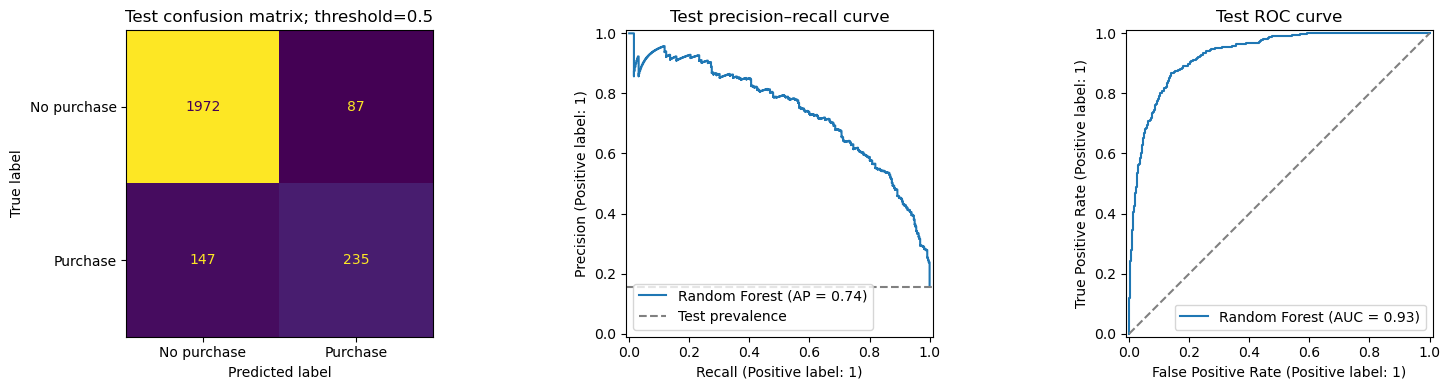

Correctly identified buyers: 235; missed buyers: 147; false purchase predictions: 87.
AP improvement over constant-score reference: 0.5856


In [16]:
fig,axes=plt.subplots(1,3,figsize=(16,4))
ConfusionMatrixDisplay.from_predictions(yt,pred,display_labels=['No purchase','Purchase'],ax=axes[0],colorbar=False)
axes[0].set_title(f'Test confusion matrix; threshold={THRESHOLD}')
PrecisionRecallDisplay.from_predictions(yt,p,ax=axes[1],name='Random Forest')
axes[1].axhline(yt.mean(),ls='--',color='gray',label='Test prevalence');axes[1].legend();axes[1].set_title('Test precision–recall curve')
RocCurveDisplay.from_predictions(yt,p,ax=axes[2],name='Random Forest');axes[2].plot([0,1],[0,1],'--',color='gray');axes[2].set_title('Test ROC curve')
fig.tight_layout();fig.savefig(OUT/'test_performance.png',dpi=150);plt.show(); plt.close(fig)

tn, fp, fn, tp = metrics['tn_fp_fn_tp']
print(f'Correctly identified buyers: {tp}; missed buyers: {fn}; false purchase predictions: {fp}.')
print(f"AP improvement over constant-score reference: {metrics['average_precision'] - baseline['average_precision']:.4f}")

| Actual outcome | Predicted no purchase | Predicted purchase |
|---|---:|---:|
| No purchase | 1,972 | 87 |
| Purchase | 147 | 235 |

RF finds **235 of 382 buyers (61.52% recall)**. Among **322 positive predictions**, **72.98%** are correct. False positives could waste outreach; false negatives miss potential buyers.

The PR curve shows precision/recall trade-offs. ROC-AUC summarizes ranking discrimination across thresholds; it is not the percentage of correctly classified sessions. A business threshold would need contact costs and benefits and must be selected on training-validation data.

## 16 · Inspect RF Prediction Errors

In [17]:
predictions = pd.DataFrame({'record_id': test[ID].to_numpy() if ID in test else test.index.to_numpy(), TARGET: yt.to_numpy()})
predictions['purchase_probability']=p
predictions['predicted_revenue']=pred
predictions['error_type']=np.select([(yt==1)&(pred==0),(yt==0)&(pred==1)],['false_negative','false_positive'],default='correct')
predictions.to_csv(OUT/'test_predictions.csv',index=False)
# Test diagnostics are for reporting only; they cannot feed another tuning cycle.
diagnostic = test[FEATURES].copy()
diagnostic['error_type']=predictions['error_type'].to_numpy()
diagnostic.groupby('error_type')[NUM].median().to_csv(OUT/'test_error_group_medians.csv')

display(predictions.head(10))
display(predictions['error_type'].value_counts().rename('count').to_frame())
display(diagnostic.groupby('error_type')[NUM].median().round(3))

,record_id,Revenue,purchase_probability,predicted_revenue,error_type
0,1,0,0.001183,0,correct
1,4,0,0.001716,0,correct
2,5,0,0.004989,0,correct
3,9,0,0.011780,0,correct
4,11,0,0.002277,0,correct
5,13,0,0.002179,0,correct
6,16,0,0.000931,0,correct
7,21,0,0.000931,0,correct
8,38,0,0.000838,0,correct
9,54,0,0.002805,0,correct


,count
error_type,
correct,2207
false_negative,147
false_positive,87


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay
error_type,,,,,,,,,,
correct,1.0,0.000,0.0,0.0,17.0,530.583,0.003,0.027,0.000,0.0
false_negative,3.0,79.167,0.0,0.0,34.0,1262.652,0.005,0.023,0.132,0.0
false_positive,4.0,92.500,0.0,0.0,32.0,1074.683,0.000,0.016,17.991,0.0


Missed buyers have median PageValues **0.13**, compared with **17.99** for false positives. Median product-page counts are **34** and **32**, respectively. These are descriptive error-group summaries, rather than explanations of individual failures.

Cart additions, product prices, stock availability, campaign exposure and exit reasons could help a human investigate mistakes. Test-error analysis is for reporting only and does not trigger another tuning cycle.

## 17 · Explain RF Predictions with Permutation Importance

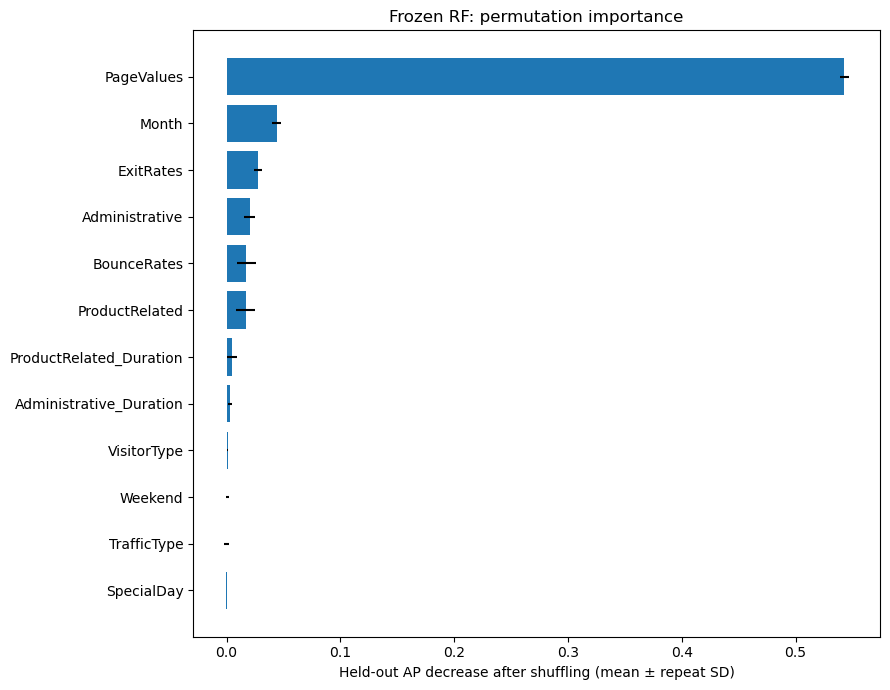

,feature,ap_drop_mean,ap_drop_std
8,PageValues,0.54282,0.00383
10,Month,0.04404,0.00416
7,ExitRates,0.02743,0.00349
0,Administrative,0.02054,0.00490
6,BounceRates,0.01755,0.00814
4,ProductRelated,0.01684,0.00811
5,ProductRelated_Duration,0.00488,0.00461
1,Administrative_Duration,0.00306,0.00163
15,VisitorType,0.00118,0.00039
16,Weekend,0.00052,0.00125


Largest observed AP decrease: PageValues (0.5428).
This is predictive association, not a causal effect.


In [18]:
importance = permutation_importance(frozen_model,Xt,yt,scoring='average_precision',
                                    n_repeats=8,random_state=SEED,n_jobs=JOBS)
imp=pd.DataFrame({'feature':FEATURES,'ap_drop_mean':importance.importances_mean,
                  'ap_drop_std':importance.importances_std}).sort_values('ap_drop_mean',ascending=False)
imp.to_csv(OUT/'permutation_importance.csv',index=False)
fig,ax=plt.subplots(figsize=(9,7));g=imp.head(12).iloc[::-1]
ax.barh(g.feature,g.ap_drop_mean,xerr=g.ap_drop_std)
ax.set(xlabel='Held-out AP decrease after shuffling (mean ± repeat SD)',title='Frozen RF: permutation importance')
fig.tight_layout();fig.savefig(OUT/'feature_importance.png',dpi=150);plt.show(); plt.close(fig)

display(imp.round(5))
print(f"Largest observed AP decrease: {imp.iloc[0]['feature']} ({imp.iloc[0]['ap_drop_mean']:.4f}).")
print('This is predictive association, not a causal effect.')

Permutation importance shuffles each original input, including PageValues, for the frozen model on all test rows (8 repeats).

| Feature | Mean AP decrease after shuffling |
|---|---:|
| PageValues | 0.5428 |
| Month | 0.0440 |
| ExitRates | 0.0274 |
| Administrative | 0.0205 |
| BounceRates | 0.0176 |

The largest decrease is for **PageValues (0.5428)**, indicating strong predictive dependence. It does not establish a causal effect or verify when that input is available. Correlated inputs can share importance, and error bars are repeat-shuffle SDs. Importance results do not guide further feature selection.

## 18 · Quantify Fixed-Model Test Uncertainty

In [19]:
rng=np.random.default_rng(SEED);ap_samples=[];auc_samples=[]
yarr=yt.to_numpy()
for _ in range(500):
    ix=rng.integers(0,len(yt),len(yt))
    if np.unique(yarr[ix]).size==2:
        ap_samples.append(average_precision_score(yarr[ix],p[ix]));auc_samples.append(roc_auc_score(yarr[ix],p[ix]))
intervals={'ap_95pct':np.quantile(ap_samples,[.025,.975]).tolist(),
           'roc_auc_95pct':np.quantile(auc_samples,[.025,.975]).tolist()}
save_json(intervals,OUT/'bootstrap_intervals.json')

display(pd.DataFrame(intervals, index=['lower 2.5%', 'upper 97.5%']).T)

,lower 2.5%,upper 97.5%
ap_95pct,0.697399,0.788817
roc_auc_95pct,0.918923,0.943868


Using **500 bootstrap resamples** of test rows:

| Metric | Fixed-model 95% percentile interval |
|---|---|
| AP | 0.6974-0.7888 |
| ROC-AUC | 0.9189-0.9439 |

These intervals measure test-row sampling uncertainty for this fixed model; they omit refitting, model selection, holdout reuse and future distribution shifts. Random splitting assumes representative independent sessions. No timestamps support a strong temporal evaluation. PageValues construction and pre-purchase availability remain unverified; fairness has not been established. Before live use, verify information available at the prediction time and evaluate on a new, appropriately timed sample.